# FitPulse: Gym Member Intelligence & Support Copilot
**Domain:** fitness (fictional gym chain, 1,000 members, 5 cities, Jan-Jun 2025). All data is synthetic.

**Flow:** raw CSVs -> audit -> clean -> SQLite -> SQL analysis -> segments + churn model -> ticket triage -> policy search -> freeze agent.

Run `python generate_data.py` once from the project folder before running this notebook.

In [1]:
import sys, sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'generate_data.py').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print('Project root:', ROOT)

Project root: c:\Users\hp\OneDrive\Desktop\fitpulse


## 1. Raw data and audit
The raw files contain deliberate problems. The audit counts them before anything is changed.

In [2]:
from src.data_pipeline import audit, clean_data, validate
audit()

members: 1000 rows, 6 columns
checkins: 55988 rows, 6 columns
payments: 6040 rows, 5 columns

MEMBERS
  different city spellings : 20
  different gender spellings: 9
  blank ages               : 53
  impossible ages (<16 or >90): 5

CHECKINS
  exact duplicate rows     : 120
  negative durations       : 374
  missing/bad calories     : 3661
  check-ins before join date: 7355

PAYMENTS
  exact duplicate rows     : 40
  unreadable amounts       : 15


## 2. Cleaning rules and validation
| # | Rule |
|---|---|
| 1-2 | City names trimmed and title-cased; gender mapped to male / female / unknown |
| 3 | Impossible ages (<16 or >90) set to missing, then filled with the city median |
| 4-5 | Duplicate check-ins removed; check-ins dated before the member's join date removed |
| 6-7 | Negative durations filled with the workout-type median; missing calories estimated from duration |
| 8-9 | Duplicate payments removed; unreadable amounts replaced with the member's plan fee |

In [3]:
tables = clean_data()
validate()

clean rows -> {'plans': 4, 'members': 1000, 'checkins': 48530, 'payments': 6000}
ALL CHECKS PASSED


## 3. SQL analysis (`sql/queries.sql`)
Seven queries using JOIN, GROUP BY, a CTE and window functions (`RANK`, running `SUM`).

In [4]:
import re
db = ROOT / 'data' / 'fitpulse.db'
raw_sql = (ROOT / 'sql' / 'queries.sql').read_text(encoding='utf-8')
titles = re.findall(r'-- (Q\d\..*)', raw_sql)
queries = [q.strip() for q in re.sub(r'--[^\n]*', '', raw_sql).split(';') if q.strip()]
with sqlite3.connect(db) as con:
    for title, q in zip(titles, queries):
        print(title)
        display(pd.read_sql_query(q, con).head(8))

Q1. JOIN + GROUP BY: revenue from paid payments by city and plan


,city,plan,revenue_inr
0,Bengaluru,Standard,496169
1,Bengaluru,Basic,372627
2,Bengaluru,Premium,359856
3,Bengaluru,Student,97478
4,Chennai,Standard,617588
5,Chennai,Premium,482307
6,Chennai,Basic,431568
7,Chennai,Student,157403


Q2. Monthly revenue and number of paid payments


,month,paid_payments,revenue_inr
0,2025-01,917,1265983
1,2025-02,907,1244193
2,2025-03,925,1266975
3,2025-04,927,1275973
4,2025-05,909,1258091
5,2025-06,919,1265581


Q3. Failed-payment rate by plan (conditional counting)


,plan,payments,failed_pct
0,Student,888,6.76
1,Standard,2016,6.35
2,Premium,960,6.25
3,Basic,2136,5.95


... (4 outputs left out)

Q6. Window function RANK: top 3 most active members in each city


,city,member_id,n_visits,rnk
0,Bengaluru,M0732,117,1
1,Bengaluru,M0022,116,2
2,Bengaluru,M0376,115,3
3,Chennai,M0626,113,1
4,Chennai,M0213,111,2
5,Chennai,M0419,111,2
6,Delhi,M0270,123,1
7,Delhi,M0719,119,2


Q7. Window function: running total of monthly revenue


,month,revenue_inr,running_total_inr
0,2025-01,1265983,1265983
1,2025-02,1244193,2510176
2,2025-03,1266975,3777151
3,2025-04,1275973,5053124
4,2025-05,1258091,6311215
5,2025-06,1265581,7576796


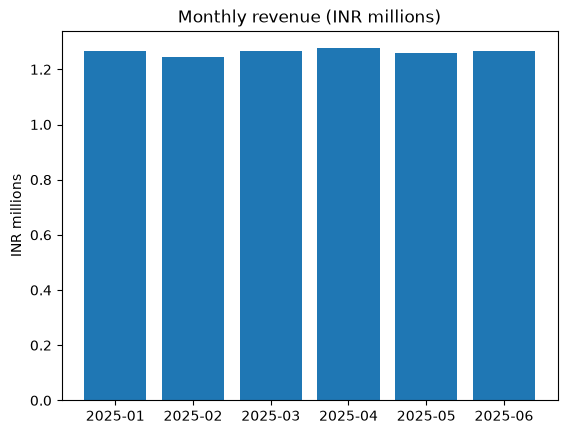

In [5]:
with sqlite3.connect(db) as con:
    monthly = pd.read_sql_query("SELECT month, SUM(amount_inr) AS revenue FROM payments WHERE status='paid' GROUP BY month", con)
plt.bar(monthly.month, monthly.revenue / 1e6)
plt.title('Monthly revenue (INR millions)'); plt.ylabel('INR millions'); plt.show()

## 4. Part B - Segments and churn
**Segments:** K-means on recency, frequency and average workout length. K=2..8 were compared with the silhouette score.
**Churn model:** features use only data before 1 June; the label is "no visit in June". The scaler and encoder are fitted inside a Pipeline on training rows only, so the test set stays unseen.

,k,inertia,silhouette
0,2,1828.6,0.425
1,3,1226.8,0.463
2,4,928.5,0.467
3,5,759.0,0.429
4,6,645.9,0.434
5,7,541.8,0.436
6,8,484.5,0.436


,segment_id,members,recency,frequency,avg_minutes,segment_name
0,0,387,3.1,36.5,54.4,Regulars
1,1,197,47.8,24.0,52.0,At Risk
2,2,146,45.3,23.7,58.3,Fading
3,3,265,0.8,98.9,54.6,Champions


PCA explained variance: [0.517 0.333] total 0.85


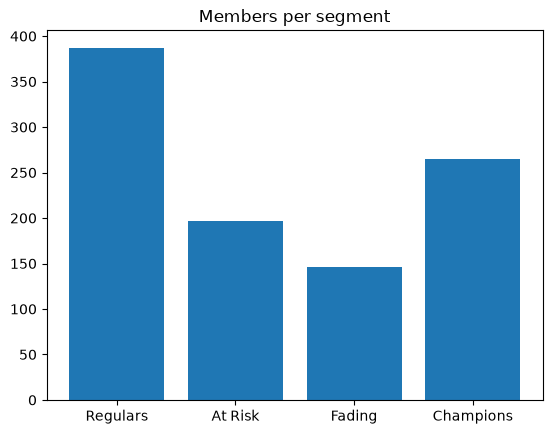

In [6]:
from src.member_models import member_segments, build_churn_model
segments, diag, profile, var = member_segments(k=4)
display(diag); display(profile)
print('PCA explained variance:', var, 'total', round(float(var.sum()), 3))
plt.bar(profile.segment_name, profile.members)
plt.title('Members per segment'); plt.show()

In [7]:
summary, results, watchlist = build_churn_model()
print(summary)
display(results)
display(watchlist[['member_id','plan','city','visits_last_30d','days_since_last_visit','churn_probability']])

{'members_modelled': 995, 'churn_rate': 0.332, 'baseline_accuracy_always_predict_stay': 0.668, 'best_model': 'forest', 'best_model_accuracy': 0.945}


,model,best_params,precision,recall,f1,confusion_matrix
0,logistic,{'model__C': 10},0.873,0.939,0.905,"[[124, 9], [4, 62]]"
1,forest,"{'model__max_depth': 5, 'model__min_samples_le...",0.887,0.955,0.920,"[[125, 8], [3, 63]]"


,member_id,plan,city,visits_last_30d,days_since_last_visit,churn_probability
79,M0080,Premium,Delhi,0.0,39,0.971
213,M0214,Standard,Chennai,0.0,31,0.971
619,M0623,Premium,Chennai,0.0,55,0.971
575,M0579,Premium,Delhi,0.0,46,0.970
138,M0139,Premium,Chennai,0.0,65,0.970
137,M0138,Premium,Chennai,0.0,37,0.968
551,M0555,Standard,Mumbai,0.0,36,0.968
456,M0459,Standard,Chennai,0.0,40,0.967
489,M0492,Student,Mumbai,0.0,31,0.967
327,M0328,Student,Chennai,0.0,30,0.966


**Reading the result:** about 33% of members churn, so "always predict stay" is already 66.8% accurate. That is why F1 is used instead of accuracy.
The score is high because the synthetic leavers fade out clearly; real gym data would be harder.

## 5. Part C - Ticket triage
Guardrails -> redaction -> (simulated) model with retries -> output validation -> routing. Invalid or risky cases go to human review.

In [8]:
from src.triage import run_pipeline, redact
result, tsum = run_pipeline()
for k, v in tsum.items(): print(k, ':', v)
display(result.groupby(['route','priority']).size().rename('tickets').reset_index())
print(redact('Call 9876543210 or mail asha@example.com about member M0123.')[0])

tickets : 168
tokens_used : 8436
personal_data_removed : {'email': 82, 'phone': 66, 'member_id': 64}
accuracy_on_classified : 1.0
status_counts : {'classified_json': 136, 'classified_keyword_fallback': 14, 'flagged_invalid_category': 10, 'flagged_too_long': 4, 'skipped_empty': 4}


,route,priority,tickets
0,billing_team,HIGH,4
1,billing_team,NORMAL,34
2,facilities_team,HIGH,7
3,facilities_team,NORMAL,31
4,human_review,HIGH,4
5,human_review,NORMAL,14
6,membership_desk,HIGH,9
7,membership_desk,NORMAL,28
8,regional_manager,HIGH,37


Call [PHONE] or mail [EMAIL] about member [MEMBER_ID].


## 6. Part D - Policy search (TF-IDF retrieval)

In [9]:
from src.policy_rag import PolicyRAG, evaluate
rag = PolicyRAG()
print('chunks:', len(rag.chunks))
print(rag.answer('How much is the freeze fee?')['answer'])
ev = evaluate(rag); display(ev)

chunks: 12
A freeze fee of INR 200 is charged for each freeze.


,question,right_document,fact_found,correctly_refused
0,What is the maximum number of days a membershi...,True,True,None
1,How much is the freeze fee?,True,True,None
2,How many days before the billing date must a f...,True,True,None
3,How much notice is needed to cancel a membership?,True,True,None
4,What is the late fee for a failed payment?,True,True,None
5,How soon is a double charge refunded?,True,True,None
6,What does a day pass for guests cost?,True,True,None
7,Are children below 16 allowed in the strength ...,True,True,None
8,What must new members complete before the firs...,True,True,None
9,How soon must an incident report be filed afte...,True,True,None


## 7. Part D - Freeze agent
Tools: `get_member`, `search_policy`, `check_freeze`, `approve_freeze`. Limits: 5 steps (then hand over to a human), token limit, time limit, checkpoint after every step.

In [10]:
import run_agent_demo
display(pd.read_csv(ROOT / 'outputs' / 'agent_results.csv')[['scenario','status','steps','answer']])

             scenario             status  steps                                                                  answer
     standard_30_days           APPROVED      4                              APPROVED: freeze for 30 days, fee INR 200.
 premium_first_freeze           APPROVED      4                                APPROVED: freeze for 20 days, fee INR 0.
premium_second_freeze           APPROVED      4                              APPROVED: freeze for 20 days, fee INR 200.
            too_short           REJECTED      3                              REJECTED: freeze must be at least 15 days.
             too_long           REJECTED      3                       REJECTED: freeze cannot exceed 60 days in a year.
             too_late           REJECTED      3     REJECTED: request must be made at least 3 days before billing date.
       unknown_member          NOT_FOUND      1                                              NOT_FOUND: no such member.
         missing_info         NEEDS_INFO

,scenario,status,steps,answer
0,standard_30_days,APPROVED,4,"APPROVED: freeze for 30 days, fee INR 200."
1,premium_first_freeze,APPROVED,4,"APPROVED: freeze for 20 days, fee INR 0."
2,premium_second_freeze,APPROVED,4,"APPROVED: freeze for 20 days, fee INR 200."
3,too_short,REJECTED,3,REJECTED: freeze must be at least 15 days.
4,too_long,REJECTED,3,REJECTED: freeze cannot exceed 60 days in a year.
5,too_late,REJECTED,3,REJECTED: request must be made at least 3 days...
6,unknown_member,NOT_FOUND,1,NOT_FOUND: no such member.
7,missing_info,NEEDS_INFO,0,"NEEDS_INFO: please give member id, number of d..."
8,confused_agent_loop,HANDOVER_MAX_STEPS,5,Handing over: 5 steps used without resolving. ...


## 8. Limitations
- All data and the "AI model" are simulated; accuracy numbers are optimistic.
- The ledger is a local file, not a billing system.
- A real deployment needs access control, monitoring and drift checks for the churn model.